# Frente B, capítulo 5: movimientos oculares y tono muscular (etapa 9)

**Módulo:** `descriptores/perifericos.py` · **Figuras:** `b_eog_*`, `b_emg_*`

## De qué se trata

REM tiene un EEG parecido al de N1, así que no se lo reconoce bien solo con el EEG. Lo
que lo delata son otras dos señales de la polisomnografía.

- El **EOG** registra los movimientos de los ojos. En REM aparecen movimientos oculares
  rápidos, que le dan nombre al estadio.
- El **EMG de mentón** registra el tono muscular. En REM el cuerpo queda casi
  paralizado (atonía), así que el EMG cae a su mínimo de la noche.

De cada una se saca un solo número por época: la energía del EOG y la amplitud del EMG.

## El recorrido de la señal

```
EOG E1 y E2                         EMG de mentón
   │                                    │
   ├─ diferencia E1 − E2                │
   ├─ épocas de 30 s                    ├─ épocas de 30 s
   ├─ energía de cada época             ├─ valor eficaz (RMS) de cada época
   └─ logaritmo                         └─ logaritmo
                     descriptores_perifericos()
```

La variabilidad de la frecuencia cardíaca (HRV) también es parte de la etapa 9, pero la
hace el Frente A, porque se calcula con los latidos que detecta en el ECG.

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base, SN122 (un
paciente de entrenamiento), y los números del texto son de ese paciente. Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian.

Las señales llegan **preprocesadas** por el Frente A (`pipeline.preprocesar`): filtradas
entre 0,2 y 45 Hz con notch en 50 Hz, sin artefacto ocular (Wiener con compuerta) y sin
artefacto cardíaco. El EMG va con un pasa-altos de 10 Hz. La señal cruda queda en
`crudo` para comparar.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    # La señal cruda se guarda para comparar; los descriptores usan la preprocesada.
    # SN122 es el paciente de ejemplo de los textos; si no está, se usa el primero.
    disponibles = ids_disponibles()
    crudo = cargar_registro("SN122" if "SN122" in disponibles else disponibles[0])
    prep = preprocesar(crudo, Config().preprocesamiento)
else:
    prep = preprocesado_sintetico(minutos=120)
    crudo = prep.registro

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. Por qué la diferencia E1 − E2

Los dos electrodos de EOG se ubican cerca de cada ojo, uno algo por encima y el otro
algo por debajo. Cuando los ojos se mueven, el globo ocular (que funciona como un
dipolo eléctrico) se acerca a un electrodo y se aleja del otro, así que la señal sube
en uno y baja en el otro. En cambio, la actividad cerebral llega casi igual a los dos.

Al restar E1 − E2, el movimiento ocular **se duplica** y la actividad cerebral **se
cancela**. La figura lo muestra en un tramo de REM.

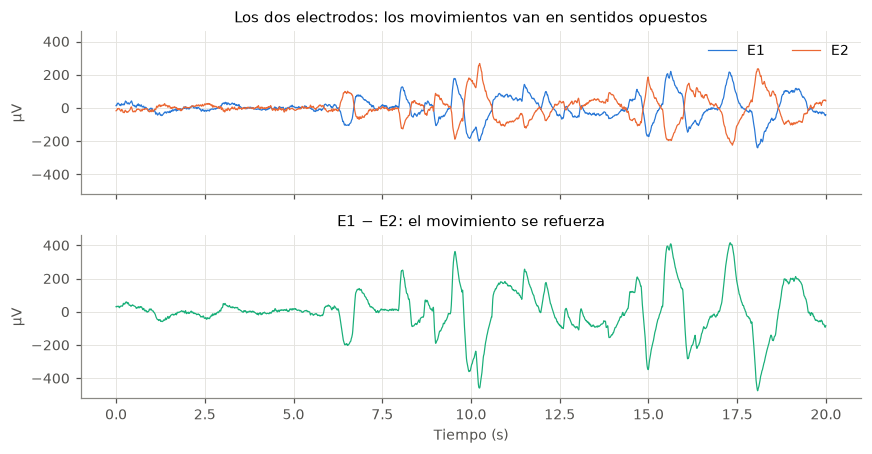

In [4]:
from estadios.comun.constantes import EMG, EOG_E1, EOG_E2, R
from estadios.descriptores import perifericos
from estadios.preprocesamiento.segmentacion import segmentar

e1, e2 = registro.senales[EOG_E1], registro.senales[EOG_E2]
n_epoca = int(30 * fs)

# La época de REM con más energía en el EOG: la de movimientos oculares más claros.
energia = perifericos.energia_por_epoca(segmentar(e1 - e2, fs, registro.n_epocas))
epocas_r = np.flatnonzero(estadios_tecnicos == R)
j = epocas_r[np.argmax(energia[epocas_r])] if len(epocas_r) else 0
ventana = slice(j * n_epoca + int(5 * fs), j * n_epoca + int(25 * fs))
t = np.arange(ventana.stop - ventana.start) / fs

fig, axs = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True, sharey=True)
axs[0].plot(t, e1[ventana], color=AZUL, lw=0.8, label="E1")
axs[0].plot(t, e2[ventana], color=NARANJA, lw=0.8, label="E2")
axs[0].set(title="Los dos electrodos: los movimientos van en sentidos opuestos", ylabel="µV")
axs[0].legend(loc="upper right", ncols=2)
axs[1].plot(t, (e1 - e2)[ventana], color=VERDE, lw=0.8)
axs[1].set(title="E1 − E2: el movimiento se refuerza", ylabel="µV", xlabel="Tiempo (s)")
fig.tight_layout()
guardar(fig, "b_eog_diferencia")

## 2. Los dos descriptores

- **Energía del EOG:** la suma de los cuadrados de E1 − E2 en la época. Crece con la
  cantidad y el tamaño de los movimientos oculares.
- **Amplitud del EMG:** el valor eficaz (RMS) del EMG en la época, es decir, la raíz
  del promedio de los cuadrados. Mide el tono muscular promedio.

Los dos se pasan a escala logarítmica, igual que la potencia absoluta del capítulo 1.
Varían en órdenes de magnitud entre pacientes y entre momentos de la noche, y en
logaritmo una época el doble de activa queda a la misma distancia sea cual sea el
nivel de partida.

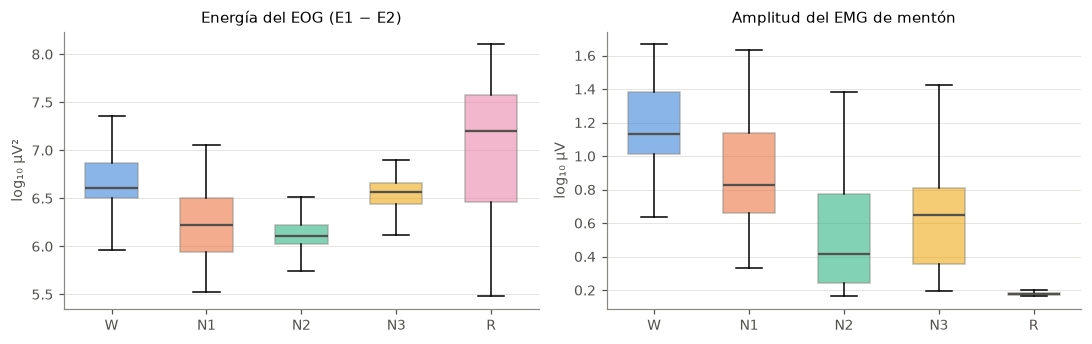

In [5]:
matriz, nombres = perifericos.descriptores_perifericos(prep, cfg)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
por_estadio(axs[0], matriz[:, nombres.index("perifericos.energia_eog")], estadios_tecnicos,
            "Energía del EOG (E1 − E2)", "log₁₀ µV²")
por_estadio(axs[1], matriz[:, nombres.index("perifericos.amplitud_emg")], estadios_tecnicos,
            "Amplitud del EMG de mentón", "log₁₀ µV")
fig.tight_layout()
guardar(fig, "b_eog_emg_por_estadio")

El EOG tiene su máximo en REM, por los movimientos oculares rápidos, y también es alto
en W, donde la persona mueve los ojos y parpadea. El EMG es máximo en W y mínimo en REM:
la atonía se ve claramente. Combinados, un EOG alto con un EMG bajo es la firma de REM,
y así lo usa la regla de REM del Frente C.

## 3. El EMG a lo largo de la noche

La atonía de REM se ve todavía mejor siguiendo el EMG durante toda la noche, debajo del
hipnograma de los técnicos.

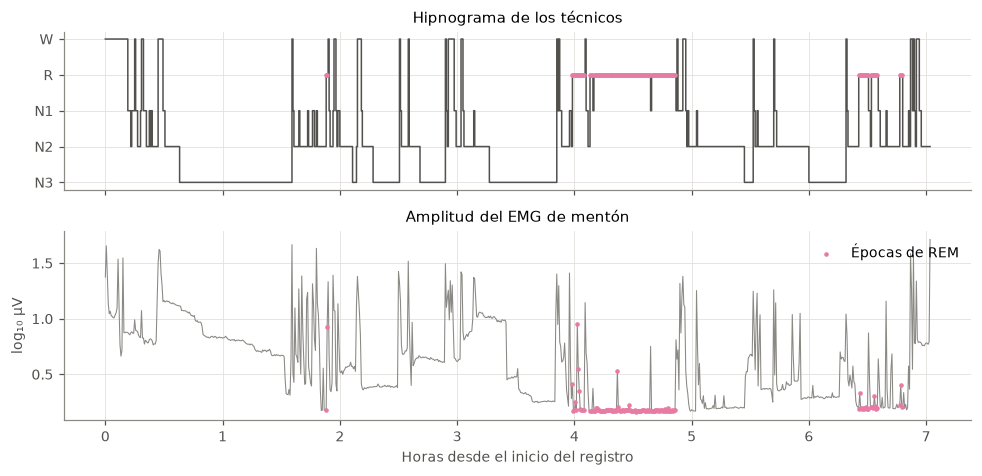

In [6]:
orden = ["N3", "N2", "N1", "R", "W"]  # De abajo hacia arriba, como se dibuja un hipnograma.
nivel = np.array([orden.index(NOMBRES_ESTADIOS[e]) if e >= 0 else np.nan for e in estadios_tecnicos])
horas = np.arange(registro.n_epocas) * 30 / 3600
emg = matriz[:, nombres.index("perifericos.amplitud_emg")]

fig, axs = plt.subplots(2, 1, figsize=(9, 4.4), sharex=True, height_ratios=[1, 1.2])
axs[0].step(horas, nivel, where="post", color=TINTA, lw=1)
en_r = estadios_tecnicos == R
axs[0].scatter(horas[en_r], nivel[en_r], s=4, color=COLOR_ESTADIO["R"], zorder=3)
axs[0].set(yticks=range(len(orden)), yticklabels=orden, title="Hipnograma de los técnicos")
axs[1].plot(horas, emg, color=GRIS, lw=0.7)
axs[1].scatter(horas[en_r], emg[en_r], s=4, color=COLOR_ESTADIO["R"], zorder=3, label="Épocas de REM")
axs[1].set(xlabel="Horas desde el inicio del registro", ylabel="log₁₀ µV", title="Amplitud del EMG de mentón")
axs[1].legend(loc="upper right")
fig.tight_layout()
guardar(fig, "b_emg_noche")

Cada vez que el hipnograma entra en REM (puntos rosados), el EMG baja a su piso de la
noche. Es el mismo patrón que describe el manual AASM.

## 4. Lo que sale de este capítulo

Dos descriptores por época: `perifericos.energia_eog` y `perifericos.amplitud_emg`.